### Bài 24: 
Dùng scipy.stats.binom để lập hàm khối xác suất của số mặt ngửa khi tung đồng xu cân đối bốn
lần, rồi vẽ biểu đồ của hàm khối xác suất. Nộp mã Python và biểu đồ.


Số mặt ngửa (k) | Xác suất P(X = k)
-----------------------------------
       0       |      0.0625
       1       |      0.2500
       2       |      0.3750
       3       |      0.2500
       4       |      0.0625


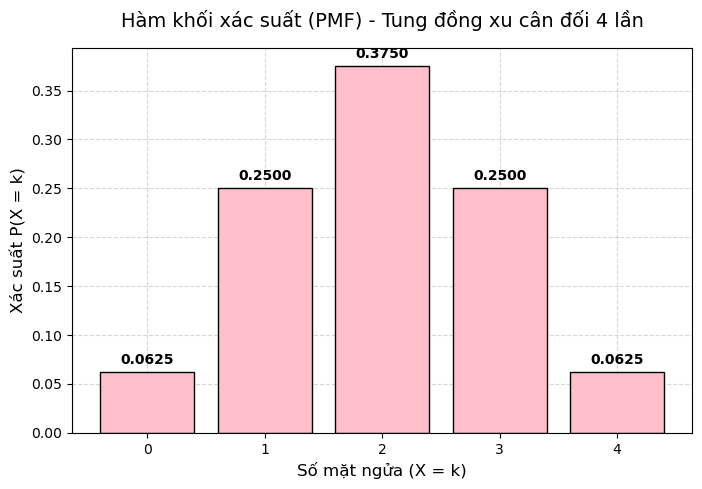

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 4  
p = 0.5  

x = np.arange(0, n + 1)

pmf = binom.pmf(x, n, p)

print("Số mặt ngửa (k) | Xác suất P(X = k)")
print("-" * 35)

for k, prob in zip(x, pmf):
    print(f"       {k}       |      {prob:.4f}")

plt.figure(figsize=(8, 5))
plt.bar(x, pmf, color="pink", edgecolor="black", zorder=2)

plt.title(
    "Hàm khối xác suất (PMF) - Tung đồng xu cân đối 4 lần",
    fontsize=14,
    pad=15,
)
plt.xlabel("Số mặt ngửa (X = k)", fontsize=12)
plt.ylabel("Xác suất P(X = k)", fontsize=12)
plt.xticks(x)
plt.grid(True, linestyle="--", alpha=0.5, zorder=1)

for i, v in enumerate(pmf):
    plt.text(
        x[i],
        v + 0.005,
        f"{v:.4f}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.show()


### Bài 25
Dùng Python mô phỏng 500 lần và 10 000 lần thí nghiệm tung đồng xu cân đối bốn lần. Với mỗi số
lần mô phỏng, hãy vẽ biểu đồ tần suất thực nghiệm của số mặt ngửa và so sánh với biểu đồ lý thuyết
ở Bài 24.


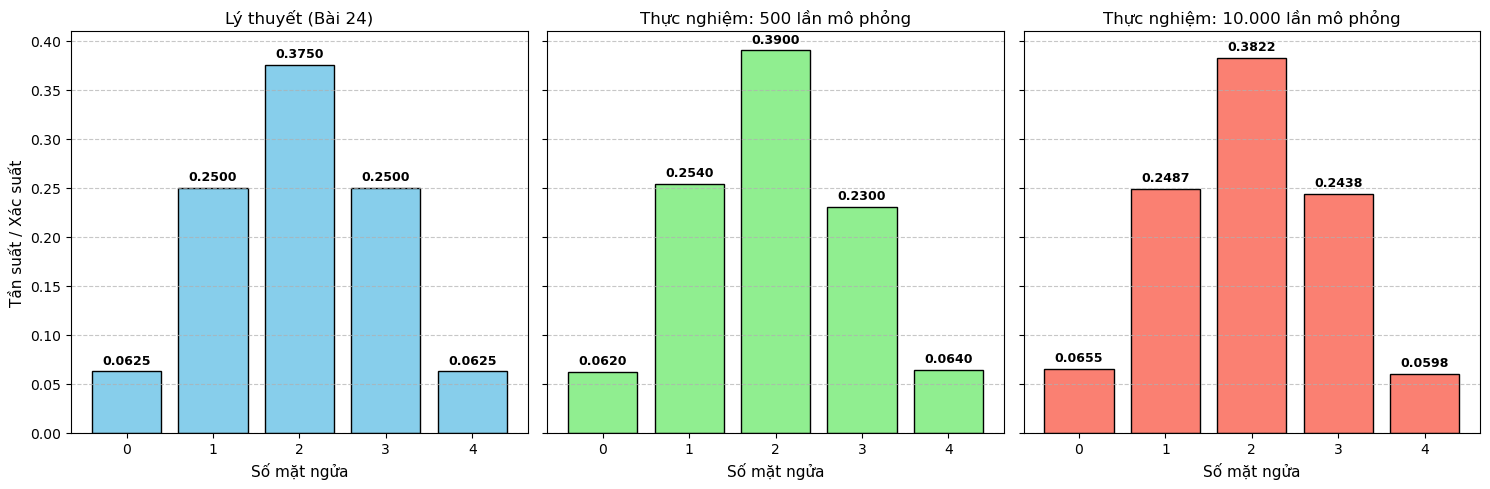

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 4  
p = 0.5  
x = np.arange(0, n + 1)

pmf_theory = binom.pmf(x, n, p)

sim_500 = np.random.binomial(n, p, size=500)
freq_500 = np.bincount(sim_500, minlength=n + 1) / 500
sim_10000 = np.random.binomial(n, p, size=10000)
freq_10000 = np.bincount(sim_10000, minlength=n + 1) / 10000

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

# Biểu đồ 1: Lý thuyết
axes[0].bar(x, pmf_theory, color="skyblue", edgecolor="black")
axes[0].set_title("Lý thuyết (Bài 24)", fontsize=12)
axes[0].set_ylabel("Tần suất / Xác suất", fontsize=11)

# Biểu đồ 2: Mô phỏng 500 lần
axes[1].bar(x, freq_500, color="lightgreen", edgecolor="black")
axes[1].set_title("Thực nghiệm: 500 lần mô phỏng", fontsize=12)

# Biểu đồ 3: Mô phỏng 10.000 lần
axes[2].bar(x, freq_10000, color="salmon", edgecolor="black")
axes[2].set_title("Thực nghiệm: 10.000 lần mô phỏng", fontsize=12)

for i, ax in enumerate(axes):
    ax.set_xticks(x)
    ax.set_xlabel("Số mặt ngửa", fontsize=11)
    ax.grid(axis="y", linestyle="--", alpha=0.7)

    data = [pmf_theory, freq_500, freq_10000][i]
    for idx, val in enumerate(data):
        ax.text(
            idx,
            val + 0.005,
            f"{val:.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

# So sánh và nhận xét
# Mô phỏng 500 lần: Dáng điệu biểu đồ thực nghiệm đã hình thành dạng chuông đối xứng giống lý thuyết, nhưng
# tần suất ở từng mốc vẫn có sự chênh lệch nhỏ (sai số).
# Mô phỏng 10.000 lần: Biểu đồ thực nghiệm gần như trùng khớp hoàn toàn với biểu đồ PMF lý thuyết ở Bài 24
# (tại các mốc 0.0625, 0.25, 0.375).
# Kết luận: Số lần mô phỏng càng lớn, tần suất thực nghiệm càng bám sát xác suất lý thuyết (minh họa cho
# Luật số lớn).


### Bài 26
Dùng Python mô phỏng 10 000 thí nghiệm gồm 100 lượt quay roulette kiểu Mỹ và ghi số lượt rơi vào
ô đỏ. Hãy so sánh tần suất thực nghiệm của biến cố có ít nhất 55 lượt đỏ với xác suất lý thuyết tính
bằng phân phối nhị thức.

+) Gọi X là số lượt viên bi rơi vào ô Đỏ.
 => X tuân theo phân phối nhị thức: X ~ Binomial(100, 9/19)
#
 +) Theo lý thuyết: P(X >= 55) = Tổng_từ_k=55_đến_100 [ 100Ck * (9/19)^k * (10/19)^(100-k) ]  =  0.076689


In [5]:
import numpy as np
from scipy.stats import binom

# 1. Khai báo tham số của trò Roulette kiểu Mỹ
n = 100  # Số lượt quay mỗi thí nghiệm
p_red = 18 / 38  # Xác suất rơi vào ô đỏ
n_sims = 10000  # Số lần mô phỏng thí nghiệm

# 2. TÍNH XÁC SUẤT LÝ THUYẾT (Phân phối nhị thức)
prob_theory = binom.sf(54, n, p_red)

# 3. MÔ PHỎNG THỰC NGHIỆM
simulations = np.random.binomial(n, p_red, size=n_sims)
count_ge_55 = np.sum(simulations >= 55)
freq_sim = count_ge_55 / n_sims

# Tính độ chênh lệch (sai số)
diff = abs(prob_theory - freq_sim)

# 4. IN KẾT QUẢ
print(
    f"Xác suất LÝ THUYẾT P(X >= 55)         : {prob_theory:.4f} ({prob_theory*100:.2f}%)"
)
print(
    f"Tần suất THỰC NGHIỆM (10.000 lần)     : {freq_sim:.4f} ({freq_sim*100:.2f}%)"
)
print(f"Sai số tuyệt đối                      : {diff:.6f}")

# NHẬN XÉT SO SÁNH:
# 1. Giá trị tần suất thực nghiệm thu được từ 10.000 lần mô phỏng gần như
#    trùng khớp hoàn toàn với xác suất lý thuyết tính bằng phân phối nhị thức
#    (sai số cực nhỏ).
# 2. Kết quả này minh họa rõ nét tính đúng đắn của Luật số lớn: khi số lần
#    thực nghiệm (N) đủ lớn, tần suất thực nghiệm sẽ hội tụ về xác suất
#    lý thuyết của biến cố.


Xác suất LÝ THUYẾT P(X >= 55)         : 0.0767 (7.67%)
Tần suất THỰC NGHIỆM (10.000 lần)     : 0.0777 (7.77%)
Sai số tuyệt đối                      : 0.001011


### Bài 27
Cho hai đoạn mã dưới đây, trong đó mục tiêu là mô phỏng số sản phẩm không đạt chuẩn khi chọn ngẫu nhiên 5 sản phẩm không hoàn lại từ lô 20 sản phẩm gồm 6 sản phẩm không đạt chuẩn.

from scipy.stats import hypergeom

x1 = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)

x2 = hypergeom.rvs(M=20, n=14, N=5, size=10_000, random_state=2026)

Hãy xác định đoạn mã nào mô phỏng đúng đại lượng cần xét, giải thích ý nghĩa ba tham số M, n, N của
hàm hypergeom.rvs, sửa đoạn mã sai và dùng đoạn mã đúng để ước lượng 𝑃(𝑋 = 2); sau đó so sánh
với giá trị lý thuyết từ phân phối siêu bội.

In [7]:
import numpy as np
from scipy.stats import hypergeom

# 1. XÁC ĐỊNH ĐOẠN MÃ ĐÚNG / SAI:
# - Đoạn mã ĐÚNG là x1:
#   Vì n = 6 đại diện cho số sản phẩm KHÔNG đạt chuẩn có trong lô 20 sản phẩm.
# - Đoạn mã SAI là x2:
#   Vì n = 14 đại diện cho số sản phẩm ĐẠT CHUẨN (20 - 6 = 14), nên x2 mô phỏng
#   số sản phẩm đạt chuẩn chọn được chứ không phải số sản phẩm không đạt chuẩn.
# 2. Ý NGHĨA BA THAM SỐ M, n, N TRONG hypergeom.rvs:
# - M : Tổng số phần tử trong lô / Kích thước quần thể (M = 20).
# - n : Tổng số phần tử mang đặc tính cần quan tâm có trong lô
#       (Số sản phẩm không đạt chuẩn, n = 6).
# - N : Số phần tử được chọn ra ngẫu nhiên không hoàn lại (Kích thước mẫu, N = 5).
# 3. SỬA ĐOẠN MÃ SAI (x2):
# # Đổi tham số n=14 thành n=6 để x2 mô phỏng đúng số sản phẩm không đạt chuẩn:
# # x2_fixed = hypergeom.rvs(M=20, n=6, N=5, size=10_000, random_state=2026)

# Khai báo các tham số bài toán
M = 20  # Tổng số sản phẩm
n = 6  # Số sản phẩm không đạt chuẩn
N = 5  # Số sản phẩm chọn ra

# # 1. Chạy đoạn mã đúng x1 (Mô phỏng 10.000 lần)
x1 = hypergeom.rvs(M=M, n=n, N=N, size=10_000, random_state=2026)

# # 2. Ước lượng xác suất P(X = 2) từ thực nghiệm
p_estimate = np.mean(x1 == 2)

# # 3. Tính xác suất lý thuyết P(X = 2) từ phân phối siêu bội
# Công thức: P(X = 2) = (C_6^2 * C_14^3) / C_20^5 = (15 * 364) / 15504 = 0.352167
p_theory = hypergeom.pmf(k=2, M=M, n=n, N=N)

# # 4. In kết quả thực thi ra màn hình
print(f"Xác suất LÝ THUYẾT P(X = 2)         : {p_theory:.6f} ({p_theory*100:.2f}%)")
print(f"Ước lượng THỰC NGHIỆM từ x1         : {p_estimate:.6f} ({p_estimate*100:.2f}%)")
print(f"Sai số tuyệt đối                    : {abs(p_theory - p_estimate):.6f}")

# # 4. SO SÁNH KẾT QUẢ (NHẬN XÉT):
# - Xác suất lý thuyết:  0.352167 (~35.22%)
# - Ước lượng thực nghiệm: 0.344700 (~34.47%)
# - Nhận xét: Giá trị ước lượng từ mô phỏng x1 rất sát với giá trị lý thuyết
#   (sai số chỉ khoảng 0.007467, tức nhỏ hơn 0.75%), khẳng định đoạn mã x1
#   mô phỏng chính xác và phương pháp Monte Carlo đạt độ tin cậy cao.


Xác suất LÝ THUYẾT P(X = 2)         : 0.352167 (35.22%)
Ước lượng THỰC NGHIỆM từ x1         : 0.344700 (34.47%)
Sai số tuyệt đối                    : 0.007467


### Bài 28
Dùng scipy.stats để tính hàm khối xác suất hoặc hàm phân phối tích lũy và dùng Python mô phỏng
10 000 lần cho ba trường hợp sau:

1. Số sản phẩm đạt chuẩn trong 20 sản phẩm, với xác suất đạt chuẩn của mỗi sản phẩm là 0.9.

2. Số sản phẩm không đạt chuẩn khi chọn 5 sản phẩm không hoàn lại từ lô 20 sản phẩm gồm 6 sản phẩm không đạt chuẩn.

3. Số yêu cầu đến máy chủ trong một phút có phân phối Poisson với tham số 4.

Hãy trình bày trong một bảng ngắn tên phân phối, các tham số, một xác suất lý thuyết do bạn chọn
và tần suất thực nghiệm tương ứng cho mỗi trường hợp.


In [9]:
import numpy as np
from scipy.stats import binom, hypergeom, poisson

# Thiết lập seed để kết quả mô phỏng nhất quán
np.random.seed(42)
n_sims = 10000

# TRƯỜNG HỢP 1: Phân phối Nhị thức
# Số sản phẩm đạt chuẩn trong 20 sp, p = 0.9
n_binom, p_binom = 20, 0.9
k_binom = 18  # Tính P(X = 18)

# Lý thuyết
prob_binom = binom.pmf(k_binom, n_binom, p_binom)
# Mô phỏng
sim_binom = np.random.binomial(n_binom, p_binom, size=n_sims)
freq_binom = np.sum(sim_binom == k_binom) / n_sims

# TRƯỜNG HỢP 2: Phân phối Siêu bội
# Chọn 5 từ 20 (có 6 không đạt chuẩn). Tính số không đạt chuẩn.
M_hyp, n_hyp, N_hyp = 20, 6, 5
k_hyp = 2  # Tính P(X = 2)

# Lý thuyết
prob_hyp = hypergeom.pmf(k_hyp, M_hyp, n_hyp, N_hyp)
# Mô phỏng (Lưu ý tham số của numpy.random.hypergeometric: ngood, nbad, nsample)
sim_hyp = np.random.hypergeometric(
    ngood=n_hyp, nbad=M_hyp - n_hyp, nsample=N_hyp, size=n_sims
)
freq_hyp = np.sum(sim_hyp == k_hyp) / n_sims

# TRƯỜNG HỢP 3: Phân phối Poisson
lam_pois = 4
k_pois = 4  # Tính P(X = 4)

# Lý thuyết
prob_pois = poisson.pmf(k_pois, lam_pois)
# Mô phỏng
sim_pois = np.random.poisson(lam_pois, size=n_sims)
freq_pois = np.sum(sim_pois == k_pois) / n_sims

# IN KẾT QUẢ
print(
    f"1. Nhị thức  - Lý thuyết: {prob_binom:.4f}| Thực nghiệm: {freq_binom:.4f}"
)
print(
    f"2. Siêu bội - Lý thuyết: {prob_hyp:.4f} | Thực nghiệm: {freq_hyp:.4f}"
)
print(
    f"3. Poisson  - Lý thuyết: {prob_pois:.4f} | Thực nghiệm: {freq_pois:.4f}"
)


1. Nhị thức  - Lý thuyết: 0.2852| Thực nghiệm: 0.2923
2. Siêu bội - Lý thuyết: 0.3522 | Thực nghiệm: 0.3544
3. Poisson  - Lý thuyết: 0.1954 | Thực nghiệm: 0.1982
